**Célula 1 – setup:**

In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

%load_ext autoreload
%autoreload 2

import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap

from src.utils import set_seed, SEED, CLASS_NAMES, get_splits
from src.representation import fit_pca, pca_project

set_seed()
X_train, y_train, X_val, y_val, X_test, y_test = get_splits()

c:\Users\andre\OneDrive\Documentos\UBI\ML\PROJETO2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Célula 2 – subconjunto equilibrado (500 por classe):**

In [2]:
rng = np.random.default_rng(SEED)
n_per_class = 500

idx_subset = np.concatenate([
    rng.choice(np.where(y_train == c)[0], size=n_per_class, replace=False)
    for c in range(10)
])
X_sub, y_sub = X_train[idx_subset], y_train[idx_subset]
print("Subconjunto:", X_sub.shape, "| por classe:", np.bincount(y_sub))

Subconjunto: (5000, 784) | por classe: [500 500 500 500 500 500 500 500 500 500]


**Célula 3 – as três projeções 2D:**

In [3]:
embeddings = {} 

pca = fit_pca(X_train)
embeddings["PCA (linear)"] = pca_project(pca, X_sub, 2)

start = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED)
embeddings["t-SNE"] = tsne.fit_transform(X_sub)
print(f"t-SNE: {time.perf_counter() - start:.1f} s")

start = time.perf_counter()
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)
embeddings["UMAP"] = reducer.fit_transform(X_sub)
print(f"UMAP: {time.perf_counter() - start:.1f} s")

t-SNE: 31.6 s


c:\Users\andre\OneDrive\Documentos\UBI\ML\PROJETO2\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP: 39.7 s


**Célula 4 – gráfico lado a lado:**

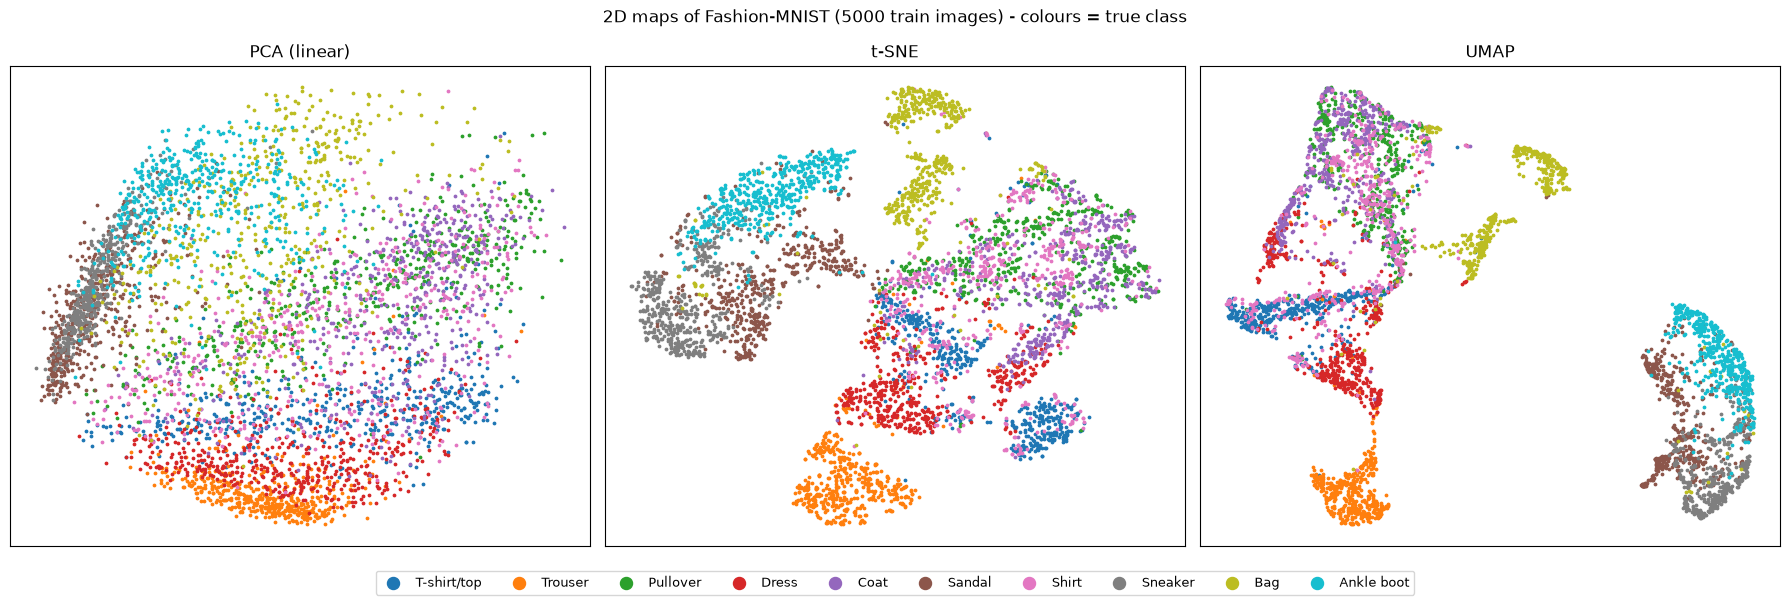

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
cmap = plt.get_cmap("tab10")   

for ax, (name, emb) in zip(axes, embeddings.items()):
    for c in range(10):
        mask = y_sub == c                                   
        ax.scatter(emb[mask, 0], emb[mask, 1], s=3, color=cmap(c), label=CLASS_NAMES[c])
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])                    

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=10, markerscale=5, fontsize=9)
plt.suptitle("2D maps of Fashion-MNIST (5000 train images) - colours = true class")
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("results/figures/05_pca_tsne_umap_2d.png", dpi=150, bbox_inches="tight")
plt.show()